# Fase 6: Mezcla de modelos y optimización por calidad de probabilidad
**Tesis:** Modelo Predictivo de Resultados — Premier League 2017–2025
**Objetivo:** Comprobar si **promediar las probabilidades** de varios modelos bien calibrados mejora la predicción respecto de cada modelo por separado.
**Input:** `Dataset/model_dataset_selected.csv` (28 variables) y las 3 probabilidades de las cuotas de `model_dataset_enriched.csv`
**Output:** `resultados/mezcla_modelos_*.csv`, `Imagenes/mezcla_modelos/*.png`

## ¿Qué se prueba y por qué?
Una **mezcla** combina las probabilidades de varios modelos, como pedir la opinión a varios analistas y promediarla. Solo ayuda si los modelos se equivocan en partidos distintos; si todos dependen de la misma señal (aquí, las cuotas), el aporte será pequeño.

| Modelo base | Por qué se incluye |
|---|---|
| **Solo cuotas** (Reg. Logística sobre las 3 probabilidades implícitas) | Es la referencia más fuerte y estable |
| **Regresión Logística** (28 variables) | Aporta señal lineal adicional con poco riesgo de sobreajuste |
| **Random Forest** (28 variables) | Familia no lineal distinta; mejor accuracy individual hasta ahora |

**Mezcla A (la que se evalúa):** promedio simple, con el mismo peso, de las tres. No tiene pesos que aprender, así que no hay riesgo de sobreajustar la mezcla.

## Optimización por calidad de probabilidad
Hasta ahora los modelos usaban `class_weight='balanced'` y se afinaban por F1, lo que **distorsiona las probabilidades**. Aquí:
1. Se entrena **sin pesos de clase**.
2. Los hiperparámetros se eligen por **log-loss** con validación temporal interna (solo datos de entrenamiento).
3. El Random Forest se **calibra** (método sigmoide) con validación temporal interna.
4. La regresión logística ya produce probabilidades calibradas.

Con probabilidades calibradas, predecir "gana el local" cuando la probabilidad supera 0,5 es lo óptimo para el accuracy.

## Protocolo (declarado ANTES de ver los resultados)
1. **Métrica principal: log-loss** (calidad de probabilidad); también ROC-AUC, Brier y accuracy.
2. **Desarrollo = folds 1 a 4** (2018-19 a 2021-22) y **confirmación = folds 5 a 7** (2022-23 a 2024-25), que se reportan una sola vez.
3. La mezcla se considera mejor solo si **mejora el log-loss en desarrollo y se confirma en las temporadas de confirmación**.
4. Se registra todo lo probado, incluso si no ayuda.

## 1. Configuración y carga de datos

In [1]:
import os, sys, json, time, warnings
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import accuracy_score, roc_auc_score, brier_score_loss, log_loss

sys.path.insert(0, '.')
from utils.split_utils import expanding_window_split

sns.set_theme(style='whitegrid', palette='muted'); plt.rcParams['figure.dpi'] = 120
os.makedirs('Imagenes/mezcla_modelos', exist_ok=True)
TARGET = 'target_home_win'

df = pd.read_csv('Dataset/model_dataset_selected.csv')
enr = pd.read_csv('Dataset/model_dataset_enriched.csv')
assert len(enr) == len(df) and (enr[TARGET].values == df[TARGET].values).all()
X = df.drop(columns=[TARGET, 'season']); y = df[TARGET]
CUOTAS = enr[['odds_home_prob', 'odds_draw_prob', 'odds_away_prob']]
folds = expanding_window_split(df, min_train_seasons=1)
with open('resultados/baseline_mercado_por_temporada.json', encoding='utf-8') as f:
    MERCADO = pd.Series(json.load(f)['por_temporada'])
print(f'Partidos: {len(df)} | variables: {X.shape[1]} | folds: {len(folds)}')

Partidos: 2973 | variables: 28 | folds: 7


## 2. Modelos base calibrados
En cada fold, cada modelo elige sus hiperparámetros con `TimeSeriesSplit(3)` **dentro del entrenamiento**, minimizando el log-loss. El test nunca interviene.

In [2]:
INTERNO = lambda: TimeSeriesSplit(n_splits=3)

def ajustar_cuotas(idx_tr):
    gs = GridSearchCV(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
                      {'logisticregression__C': [0.01, 0.1, 1, 10]}, scoring='neg_log_loss', cv=INTERNO())
    gs.fit(CUOTAS.iloc[idx_tr], y.iloc[idx_tr]); return gs

def ajustar_lr(idx_tr):
    gs = GridSearchCV(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
                      {'logisticregression__C': [0.001, 0.01, 0.1, 1]}, scoring='neg_log_loss', cv=INTERNO())
    gs.fit(X.iloc[idx_tr], y.iloc[idx_tr]); return gs

def ajustar_rf(idx_tr):
    base = CalibratedClassifierCV(RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1), method='sigmoid', cv=INTERNO())
    gs = GridSearchCV(base, {'estimator__max_depth': [3, 5, 8, 12], 'estimator__min_samples_leaf': [5, 10, 20, 40]},
                      scoring='neg_log_loss', cv=INTERNO())
    gs.fit(X.iloc[idx_tr], y.iloc[idx_tr]); return gs

MODELOS = {'Solo cuotas': (ajustar_cuotas, CUOTAS), 'Reg. Logística': (ajustar_lr, X), 'Random Forest (calibrado)': (ajustar_rf, X)}

## 3. Evaluación en los 7 folds (modelos individuales y mezcla A)

In [3]:
filas, probs_guardadas, params = [], {}, []
t0 = time.time()
for fold, (tr, te, _, temporada) in enumerate(folds, 1):
    yte = y.iloc[te].values
    p = {}
    for nombre, (ajustar, datos) in MODELOS.items():
        gs = ajustar(tr)
        p[nombre] = gs.predict_proba(datos.iloc[te])[:, 1]
        params.append({'fold': fold, 'modelo': nombre, **{k: v for k, v in gs.best_params_.items()}})
    p['Mezcla A (promedio simple)'] = np.mean([p['Solo cuotas'], p['Reg. Logística'], p['Random Forest (calibrado)']], axis=0)
    probs_guardadas[fold] = (yte, p)
    for nombre, pr in p.items():
        filas.append({'fold': fold, 'temporada_test': temporada, 'etapa': 'desarrollo' if fold <= 4 else 'confirmación', 'modelo': nombre,
                      'log_loss': log_loss(yte, pr), 'roc_auc': roc_auc_score(yte, pr), 'brier': brier_score_loss(yte, pr),
                      'accuracy': accuracy_score(yte, (pr >= 0.5).astype(int))})
    print(f'fold {fold} ({temporada}) listo — {(time.time() - t0):.0f}s acumulados')
res = pd.DataFrame(filas)
res['mercado_acc'] = res['temporada_test'].map(MERCADO)
res['dif_vs_mercado_pp'] = (res['accuracy'] - res['mercado_acc']) * 100
res.to_csv('resultados/mezcla_modelos_resultados.csv', index=False)
pd.DataFrame(params).to_csv('resultados/mezcla_modelos_hiperparametros.csv', index=False)

fold 1 (2018-2019) listo — 58s acumulados


fold 2 (2019-2020) listo — 117s acumulados


fold 3 (2020-2021) listo — 178s acumulados


fold 4 (2021-2022) listo — 241s acumulados


fold 5 (2022-2023) listo — 304s acumulados


fold 6 (2023-2024) listo — 368s acumulados


fold 7 (2024-2025) listo — 433s acumulados


## 4. Desarrollo (folds 1 a 4): decisión

In [4]:
orden = ['Solo cuotas', 'Reg. Logística', 'Random Forest (calibrado)', 'Mezcla A (promedio simple)']
def tabla(etapa=None):
    r = res if etapa is None else res[res['etapa'] == etapa]
    t = r.groupby('modelo')[['log_loss', 'roc_auc', 'brier', 'accuracy']].mean().reindex(orden).round(4)
    t['dif_logloss_vs_cuotas'] = (t['log_loss'] - t.loc['Solo cuotas', 'log_loss']).round(4)
    return t

dev = tabla('desarrollo')
print('DESARROLLO (temporadas de test 2018-19 a 2021-22) — menor log-loss es mejor')
print(dev.to_string())
mejor_dev = dev['log_loss'].idxmin()
print(f'\n>>> Mejor log-loss en desarrollo: {mejor_dev}')

DESARROLLO (temporadas de test 2018-19 a 2021-22) — menor log-loss es mejor
                            log_loss  roc_auc   brier  accuracy  dif_logloss_vs_cuotas
modelo                                                                                
Solo cuotas                   0.5969   0.7342  0.2051    0.6905                 0.0000
Reg. Logística                0.6100   0.7319  0.2106    0.6865                 0.0131
Random Forest (calibrado)     0.6073   0.7260  0.2093    0.6798                 0.0104
Mezcla A (promedio simple)    0.6008   0.7352  0.2065    0.6831                 0.0039

>>> Mejor log-loss en desarrollo: Solo cuotas


## 5. Confirmación (folds 5 a 7): temporadas no usadas en la decisión
Se reportan una sola vez, sin cambiar nada después de verlas.

In [5]:
conf = tabla('confirmación')
print('CONFIRMACIÓN (2022-23 a 2024-25)')
print(conf.to_string())
mejora_dev = dev.loc['Mezcla A (promedio simple)', 'log_loss'] < dev.loc['Solo cuotas', 'log_loss']
mejora_conf = conf.loc['Mezcla A (promedio simple)', 'log_loss'] < conf.loc['Solo cuotas', 'log_loss']
print(f'\nLa mezcla supera a "Solo cuotas" en log-loss -> desarrollo: {mejora_dev} | confirmación: {mejora_conf}')
print('CRITERIO DECLARADO (mejora en desarrollo Y se confirma):', 'CUMPLIDO' if (mejora_dev and mejora_conf) else 'NO CUMPLIDO')
conf.to_csv('resultados/mezcla_modelos_confirmacion.csv'); dev.to_csv('resultados/mezcla_modelos_desarrollo.csv')

CONFIRMACIÓN (2022-23 a 2024-25)
                            log_loss  roc_auc   brier  accuracy  dif_logloss_vs_cuotas
modelo                                                                                
Solo cuotas                   0.5993   0.7377  0.2067    0.6797                 0.0000
Reg. Logística                0.6096   0.7264  0.2106    0.6841                 0.0103
Random Forest (calibrado)     0.6087   0.7271  0.2100    0.6867                 0.0094
Mezcla A (promedio simple)    0.6034   0.7340  0.2080    0.6867                 0.0041

La mezcla supera a "Solo cuotas" en log-loss -> desarrollo: False | confirmación: False
CRITERIO DECLARADO (mejora en desarrollo Y se confirma): NO CUMPLIDO


## 6. Los 7 folds y comparación con el mercado

In [6]:
todos = tabla()
print('PROMEDIO DE LOS 7 FOLDS'); print(todos.to_string())
dif = res.groupby('modelo')['dif_vs_mercado_pp'].agg(['mean', 'std']).reindex(orden).round(2)
print('\nAccuracy menos la regla simple del mercado (puntos porcentuales):'); print(dif.to_string())
print(f'\nMercado, regla simple (mismas temporadas): {MERCADO.drop("2017-2018").mean():.4f}')
todos.to_csv('resultados/mezcla_modelos_resumen.csv')

PROMEDIO DE LOS 7 FOLDS
                            log_loss  roc_auc   brier  accuracy  dif_logloss_vs_cuotas
modelo                                                                                
Solo cuotas                   0.5980   0.7357  0.2058    0.6858                 0.0000
Reg. Logística                0.6098   0.7295  0.2106    0.6855                 0.0118
Random Forest (calibrado)     0.6079   0.7265  0.2096    0.6828                 0.0099
Mezcla A (promedio simple)    0.6019   0.7347  0.2072    0.6847                 0.0039

Accuracy menos la regla simple del mercado (puntos porcentuales):
                            mean   std
modelo                                
Solo cuotas                 4.23  2.79
Reg. Logística              4.19  2.73
Random Forest (calibrado)   3.92  2.33
Mezcla A (promedio simple)  4.11  2.09

Mercado, regla simple (mismas temporadas): 0.6436


## 7. ¿La diferencia es real o ruido? Mezcla A frente a cada modelo, fold por fold

In [7]:
mez = res[res['modelo'] == 'Mezcla A (promedio simple)'].set_index('fold')
for otro in ['Solo cuotas', 'Reg. Logística', 'Random Forest (calibrado)']:
    o = res[res['modelo'] == otro].set_index('fold')
    d_ll, d_auc, d_acc = (mez['log_loss'] - o['log_loss']), (mez['roc_auc'] - o['roc_auc']), (mez['accuracy'] - o['accuracy']) * 100
    print(f'Mezcla A vs {otro:<26} log-loss: mejor en {int((d_ll < 0).sum())} de 7 folds (media {d_ll.mean():+.4f}) | '
          f'AUC: mejor en {int((d_auc > 0).sum())} de 7 (media {d_auc.mean():+.4f}) | accuracy: media {d_acc.mean():+.2f} pp (±{d_acc.std():.2f})')

Mezcla A vs Solo cuotas                log-loss: mejor en 1 de 7 folds (media +0.0039) | AUC: mejor en 3 de 7 (media -0.0010) | accuracy: media -0.12 pp (±1.21)
Mezcla A vs Reg. Logística             log-loss: mejor en 7 de 7 folds (media -0.0079) | AUC: mejor en 6 de 7 (media +0.0052) | accuracy: media -0.08 pp (±1.15)
Mezcla A vs Random Forest (calibrado)  log-loss: mejor en 6 de 7 folds (media -0.0060) | AUC: mejor en 6 de 7 (media +0.0082) | accuracy: media +0.19 pp (±0.59)


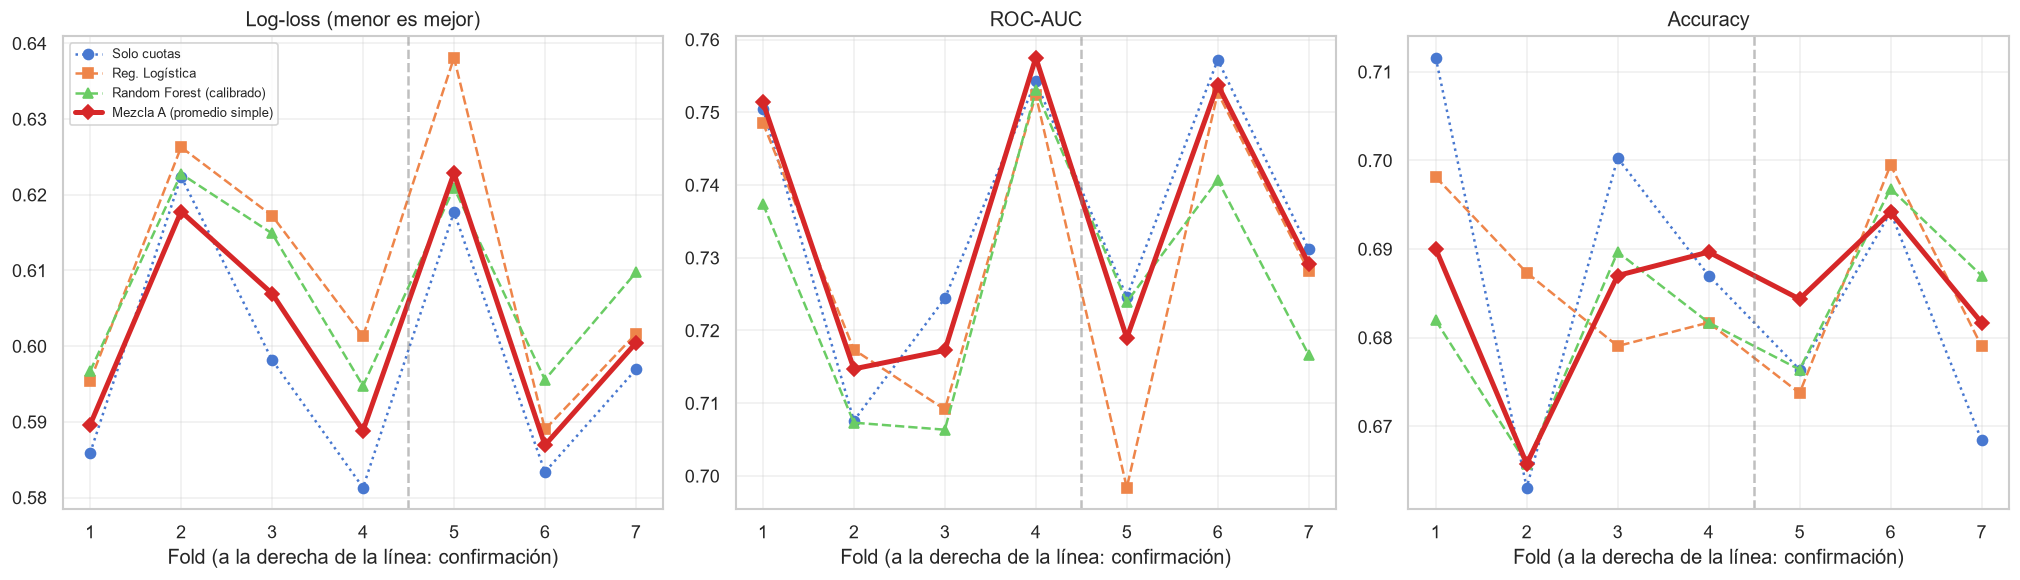

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, met, tit in zip(axes, ['log_loss', 'roc_auc', 'accuracy'], ['Log-loss (menor es mejor)', 'ROC-AUC', 'Accuracy']):
    for nombre, estilo in zip(orden, ['o:', 's--', '^--', 'D-']):
        d = res[res['modelo'] == nombre]
        ax.plot(d['fold'], d[met], estilo, lw=3 if 'Mezcla' in nombre else 1.5, label=nombre, color='#d62728' if 'Mezcla' in nombre else None)
    ax.axvline(4.5, color='gray', ls='--', alpha=0.5); ax.set_xlabel('Fold (a la derecha de la línea: confirmación)'); ax.set_title(tit); ax.grid(True, alpha=0.3)
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig('Imagenes/mezcla_modelos/comparacion_folds.png', bbox_inches='tight', dpi=120); plt.show()

## 8. Calibración de las probabilidades (7 folds agregados)

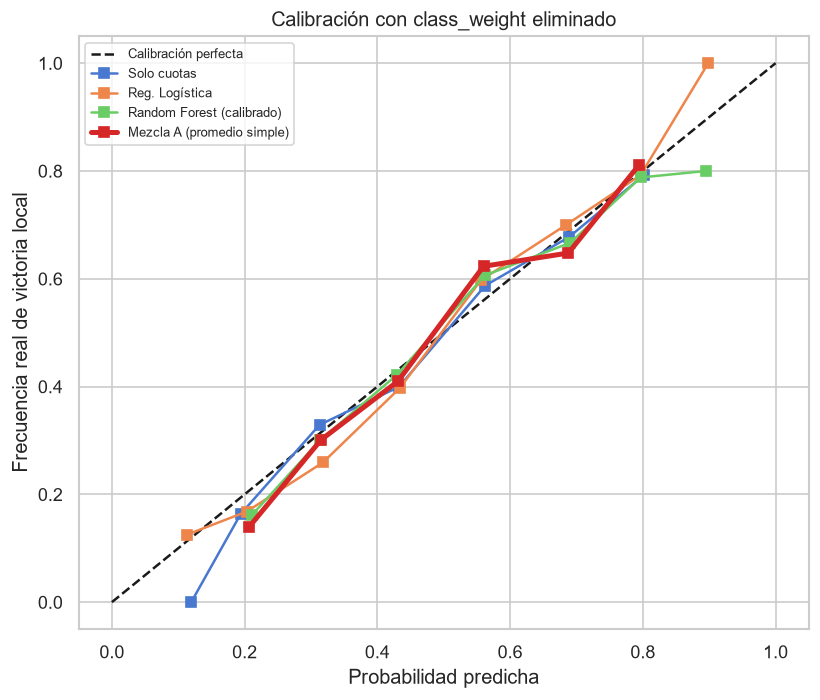

In [9]:
y_all = np.concatenate([v[0] for v in probs_guardadas.values()])
fig, ax = plt.subplots(figsize=(7, 6)); ax.plot([0, 1], [0, 1], 'k--', label='Calibración perfecta')
for nombre in orden:
    p_all = np.concatenate([v[1][nombre] for v in probs_guardadas.values()])
    pt, pp = calibration_curve(y_all, p_all, n_bins=8)
    ax.plot(pp, pt, 's-', lw=3 if 'Mezcla' in nombre else 1.5, label=nombre, color='#d62728' if 'Mezcla' in nombre else None)
ax.set_xlabel('Probabilidad predicha'); ax.set_ylabel('Frecuencia real de victoria local'); ax.set_title('Calibración con class_weight eliminado'); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig('Imagenes/mezcla_modelos/calibracion.png', bbox_inches='tight', dpi=120); plt.show()

## 9. Resumen

In [10]:
print('=' * 76); print(' RESUMEN — MEZCLA DE MODELOS'); print('=' * 76)
for nombre in orden:
    r = todos.loc[nombre]
    print(f' {nombre:<28} log-loss {r.log_loss:.4f} | AUC {r.roc_auc:.4f} | Brier {r.brier:.4f} | accuracy {r.accuracy:.4f}')
print(f' Mercado, regla simple: {MERCADO.drop("2017-2018").mean():.4f}')
print(' Criterio declarado:', 'CUMPLIDO' if (mejora_dev and mejora_conf) else 'NO CUMPLIDO', '(mejora en desarrollo y se confirma)')
print('=' * 76)

 RESUMEN — MEZCLA DE MODELOS
 Solo cuotas                  log-loss 0.5980 | AUC 0.7357 | Brier 0.2058 | accuracy 0.6858
 Reg. Logística               log-loss 0.6098 | AUC 0.7295 | Brier 0.2106 | accuracy 0.6855
 Random Forest (calibrado)    log-loss 0.6079 | AUC 0.7265 | Brier 0.2096 | accuracy 0.6828
 Mezcla A (promedio simple)   log-loss 0.6019 | AUC 0.7347 | Brier 0.2072 | accuracy 0.6847
 Mercado, regla simple: 0.6436
 Criterio declarado: NO CUMPLIDO (mejora en desarrollo y se confirma)
